In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("retail_sales_dataset - retail_sales_dataset.csv")

In [3]:
print("First 5 rows:")
display(df.head())


First 5 rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print("Dataset shape:", df.shape)


Dataset shape: (1000, 9)


In [5]:
print("\nColumn names:")
print(df.columns)



Column names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')


In [6]:

print("\nDataset information:")
df.info()




Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [7]:
print("\nStatistical summary:")
display(df.describe())


Statistical summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [8]:
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [9]:
#Identify relevant variables
print("Product categories:")
print(df["Product Category"].unique())

print("\nTotal sales amount:", df["Total Amount"].sum())

print("\nTotal quantity sold:", df["Quantity"].sum())

Product categories:
['Beauty' 'Clothing' 'Electronics']

Total sales amount: 456000

Total quantity sold: 2514


In [10]:
#Calculate total sales by product category
category_sales = df.groupby("Product Category")["Total Amount"].sum()

print(category_sales)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


In [11]:
#Sort categories by sales
category_sales = category_sales.sort_values(ascending=False)

display(category_sales)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

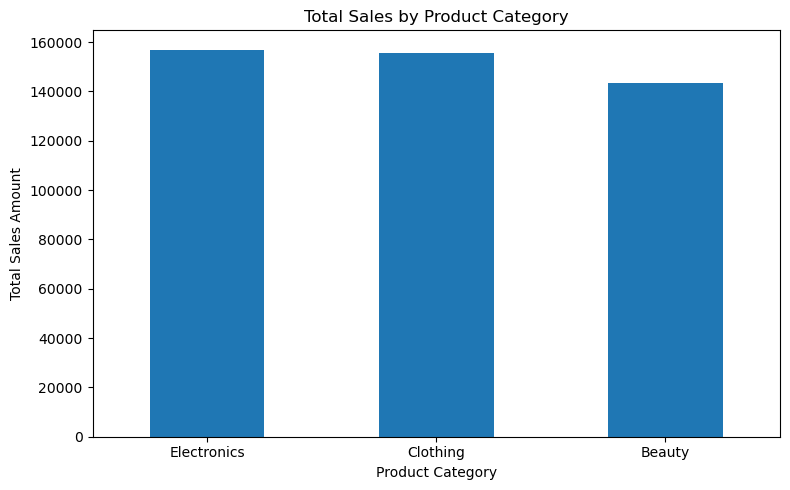

In [12]:
category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
#Identify the top-performing category
top_category = category_sales.idxmax()
highest_sales = category_sales.max()

print("Top-performing category:", top_category)
print("Highest sales amount:", highest_sales)

Top-performing category: Electronics
Highest sales amount: 156905


In [14]:
#Aggregate sales by product category and gender
gender_category_sales = df.pivot_table(
    index="Product Category",
    columns="Gender",
    values="Total Amount",
    aggfunc="sum",
    fill_value=0
)

display(gender_category_sales)

Gender,Female,Male
Product Category,,
Beauty,74830,68685
Clothing,81275,74305
Electronics,76735,80170


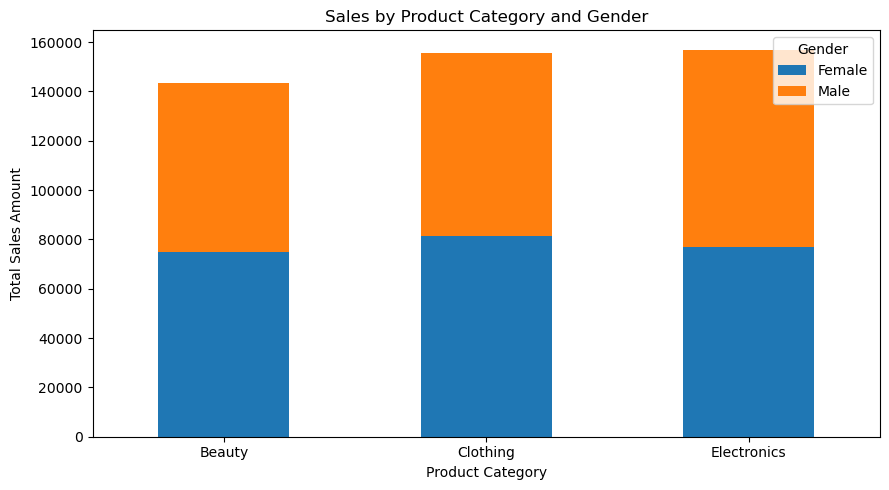

In [15]:
gender_category_sales.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Sales by Product Category and Gender")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.legend(title="Gender")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

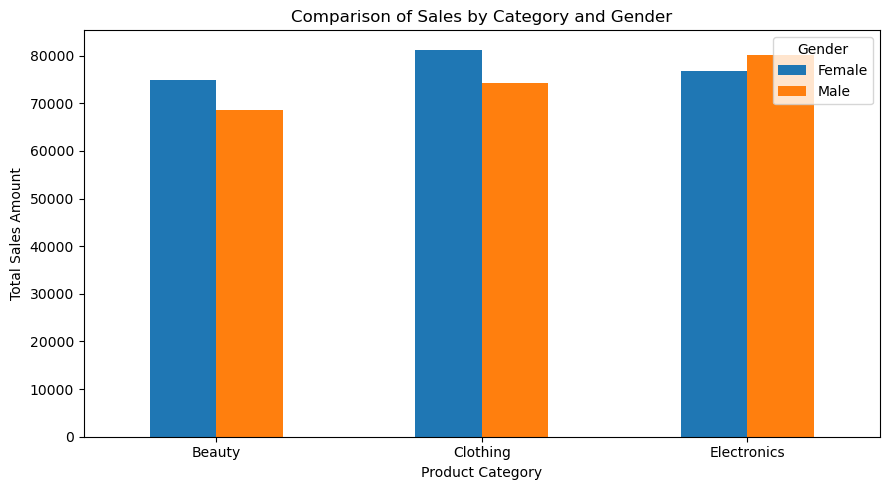

In [16]:
gender_category_sales.plot(
    kind="bar",
    stacked=False,
    figsize=(9, 5)
)

plt.title("Comparison of Sales by Category and Gender")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.legend(title="Gender")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
print("DATA AGGREGATION SUMMARY")
print("------------------------")
print("Total transactions:", len(df))
print("Total sales:", df["Total Amount"].sum())
print("Total quantity sold:", df["Quantity"].sum())
print("Number of product categories:", df["Product Category"].nunique())
print("Top-performing category:", category_sales.idxmax())
print("Highest category sales:", category_sales.max())

DATA AGGREGATION SUMMARY
------------------------
Total transactions: 1000
Total sales: 456000
Total quantity sold: 2514
Number of product categories: 3
Top-performing category: Electronics
Highest category sales: 156905
